# 07 · Initial evidence & next experiments

What did we learn, what failed, and what should the next research pass test?

Run this notebook from top to bottom. It is independent of the execution state of other notebooks.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from btc_nasdaq.config import project_root, load_config
from btc_nasdaq.research import research_context, run_period
from btc_nasdaq.plotting import set_theme, save_figure, shade_holdout, PALETTE
from btc_nasdaq.data import sha256

set_theme()
pd.options.display.float_format = "{:,.4f}".format
ROOT = project_root()
c = research_context(ROOT)
cfg, prices, returns = c["cfg"], c["prices"], c["returns"]
betas, beta, signal = c["betas"], c["beta"], c["signal"]
HOLDOUT = cfg["validation"]["holdout_start"]
summary_path = ROOT / "reports/tables/summary.json"
if not summary_path.exists():
    raise RuntimeError("Run uv run python scripts/run_research.py before executing the notebooks.")
run_record = json.loads(summary_path.read_text())
if (run_record["config_sha256"] != sha256(ROOT / "configs/research.toml") or
    run_record["data_sha256"] != sha256(ROOT / "data/processed/aligned_prices.parquet")):
    raise RuntimeError("Summary tables are stale. Re-run scripts/run_research.py.")
display(Markdown(f"**Data:** {prices.index.min():%Y-%m-%d} to {prices.index.max():%Y-%m-%d} "
                 f"· **{len(prices):,} synchronized sessions** · BTC-USD / QQQ · "
                 f"**Fixed baseline:** {cfg['strategy']['model']}"))

**Data:** 2018-01-02 to 2026-11-06 · **2,225 synchronized sessions** · BTC-USD / QQQ · **Fixed baseline:** ewma_63


### Initial result

- Aligned BTC/QQQ correlation: **-0.00** before 2020 versus **0.39** from 2020 onward.
- Fixed EWMA-63 hedge: **16.3% holdout variance reduction**, residual beta **-0.020**.
- Training Engle–Granger cointegration p-value: **0.111**.
- Fixed reversal rule: **-10.1% net holdout return**, **-0.65 Sharpe**, **-12.3% maximum drawdown**.

These results distinguish useful hedging from unproven alpha. The initial reversal rule does not establish a viable trade.


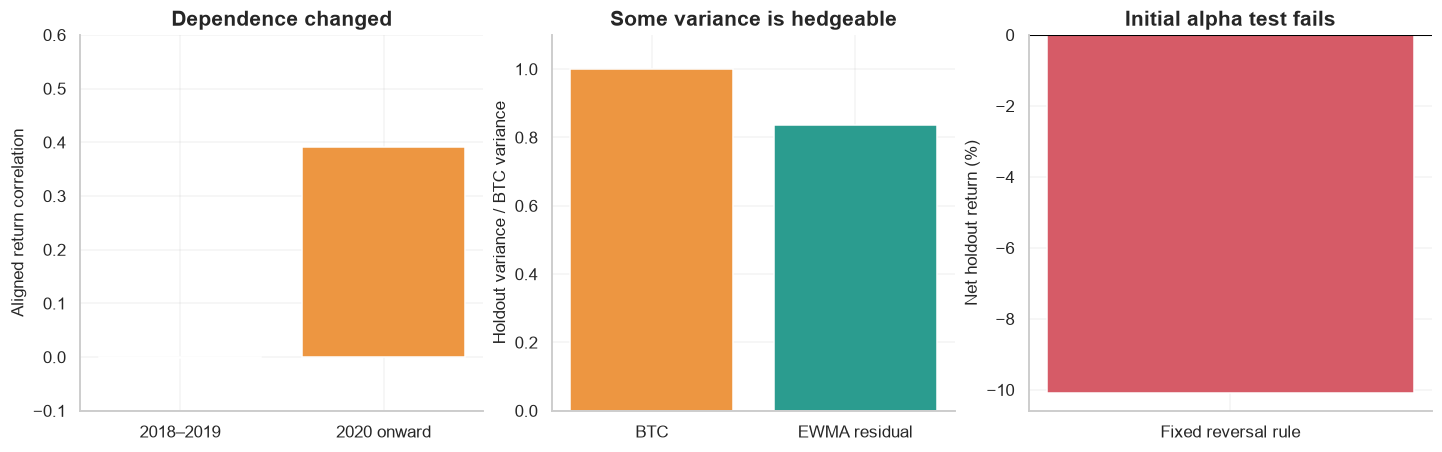

In [2]:
summary = json.loads((ROOT / "reports/tables/summary.json").read_text())
s = summary["holdout_strategy"]
h = summary["holdout_baseline_hedge"]
display(Markdown(f"""
### Initial result

- Aligned BTC/QQQ correlation: **{summary['pre_2020_correlation']:.2f}** before 2020 versus **{summary['post_2020_correlation']:.2f}** from 2020 onward.
- Fixed EWMA-63 hedge: **{h['variance_reduction']:.1%} holdout variance reduction**, residual beta **{h['residual_beta']:.3f}**.
- Training Engle–Granger cointegration p-value: **{summary['cointegration']['engle_granger_p']:.3f}**.
- Fixed reversal rule: **{s['total_return']:.1%} net holdout return**, **{s['sharpe_zero_cash']:.2f} Sharpe**, **{s['max_drawdown']:.1%} maximum drawdown**.

These results distinguish useful hedging from unproven alpha. The initial reversal rule does not establish a viable trade.
"""))
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].bar(["2018–2019", "2020 onward"], [summary["pre_2020_correlation"], summary["post_2020_correlation"]], color=PALETTE[:2])
axes[0].set(title="Dependence changed", ylabel="Aligned return correlation", ylim=(-.1, .6))
axes[1].bar(["BTC", "EWMA residual"], [1., 1.-h["variance_reduction"]], color=[PALETTE[1], PALETTE[2]])
axes[1].set(title="Some variance is hedgeable", ylabel="Holdout variance / BTC variance", ylim=(0, 1.1))
axes[2].bar(["Fixed reversal rule"], [s["total_return"]*100], color=PALETTE[4])
axes[2].axhline(0, color="black", lw=.7)
axes[2].set(title="Initial alpha test fails", ylabel="Net holdout return (%)")
save_figure(fig, ROOT, "07_initial_findings")
plt.show()

## Research decisions

| Question | First-pass read | What would change the read? |
| --- | --- | --- |
| Is the relation stronger than in 2018–2019? | Yes in this sample; it fluctuates rather than increasing monotonically | Alternative venues, synchronized higher-frequency marks, broader periods |
| Does a dynamic hedge help? | It reduces part of the variance and average linear beta | Stable performance across stress and actual execution/carry |
| Is the log-price relationship stationary? | Training cointegration evidence does not meet a 5% threshold | A justified equilibrium relation and a new out-of-sample test |
| Does the tested reversal rule earn positive net returns? | No in the initial holdout | A new economic signal with an untouched future test |
| Is this deployable? | No; it is a reproducible research baseline | Positive alpha evidence plus venue/instrument execution validation |

## Next experiments, in order

1. **Match the intended holding horizon.** Separate regular-session, overnight and weekend components
   using finer synchronized data. Estimate beta for the interval that will actually be traded.
2. **Specify an economic anchor.** Distinguish reversal after flow/liquidation shocks from reversion of
   an arbitrary cumulative residual. Consider funding, basis and liquidation features only after obtaining
   point-in-time histories with availability timestamps.
3. **Separate alpha from the risk model.** Lock a signal, compare pre-specified hedge models on
   validation, and use a new test period after selecting. Examine whether hedging removes desired alpha.
4. **Test nonlinear and multi-factor risk.** Downside betas, robust regressions and rates/dollar factors
   may explain exposure left by QQQ. Control the experiment count; do not shop for holdout Sharpe.
5. **Use the traded instruments.** QQQ versus NQ/MNQ, spot versus perpetuals, roll/funding, borrow,
   spread/slippage and margin cashflows must be modeled with the actual venue and contract histories.

**Feedback to prioritize:** intended horizon; long-only BTC dips versus symmetric reversal;
preferred Nasdaq hedge instrument; and the economic explanation for the expected reversal.
Those choices should drive the next pass more than optimizer output.

In [3]:
display(pd.Series({"sample_start": summary["sample_first"], "sample_end": summary["sample_last"],
                   "config_sha256": summary["config_sha256"], "data_sha256": summary["data_sha256"],
                   "evaluation_status": summary["status"]}, name="Reproducibility record"))

sample_start                                                2018-01-02
sample_end                                                  2026-11-06
config_sha256        a439f17693d662322554abf3d23c905c578561acff2b1c...
data_sha256          9a0981ec6532742e1cf61aec5425773123dd0ff9ea111f...
evaluation_status    Initial retrospective research; holdout examin...
Name: Reproducibility record, dtype: object

---
**Research notes / feedback**

- Observation worth following up:
- Assumption to change in the next experiment:
- Evidence that would change the conclusion:

Record changes in `docs/research_log.md`. Once you inspect a holdout, it is no longer untouched data for a new variant.